# Filter Domain Spasial: Smoothing

## Bagian 1: Import Library


In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
os.makedirs('hasil_output', exist_ok=True)


## Bagian 2 — Load dan Praproses Citra

Citra yang digunakan: **`assets/sample_banana.jpg`** — foto buah pisang 300×300px.  
Citra ini ideal untuk demonstrasi smoothing karena memiliki tekstur, warna variatif, dan tepi yang jelas.


In [2]:
img_paths = ['assets/sample_banana.jpg', '../assets/sample_banana.jpg', 'sample_banana.jpg']
img_color = None
for p in img_paths:
    if os.path.exists(p):
        img_color = cv2.imread(p)
        break

if img_color is None:
    raise FileNotFoundError("sample_banana.jpg tidak ditemukan")

img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
img_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)

print(f"Resolusi: {img_gray.shape}, min: {img_gray.min()}, mean: {img_gray.mean():.1f}, max: {img_gray.max()}")


Resolusi: (300, 300), min: 10, mean: 141.0, max: 226


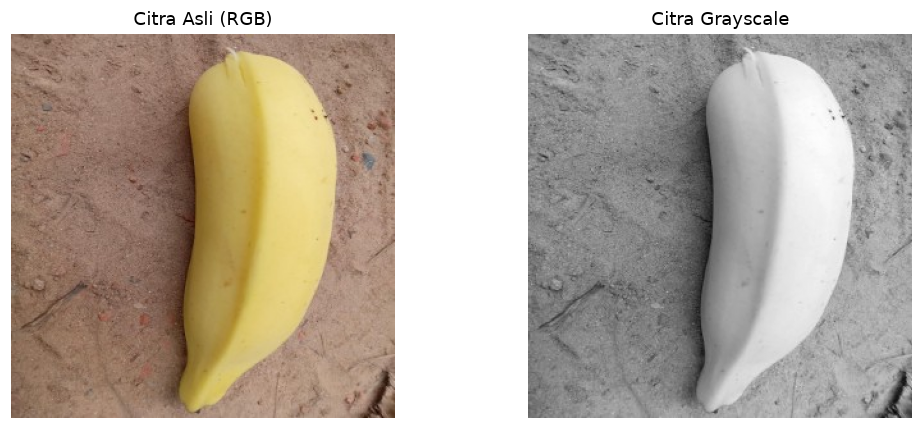

In [3]:
# Tampilkan citra asli (color & grayscale)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img_rgb)
axes[0].set_title('Citra Asli (RGB)')
axes[0].axis('off')
axes[1].imshow(img_gray, cmap='gray')
axes[1].set_title('Citra Grayscale')
axes[1].axis('off')
plt.tight_layout()
plt.show()


## Bagian 3 — Penambahan Noise (Salt & Pepper)

Smoothing/pelembutan bertujuan **mengurangi noise** pada citra.  
Agar efek filter terlihat jelas, kita tambahkan noise **salt & pepper** secara manual:
- **Salt** (garam) = piksel bernilai 255 (putih)
- **Pepper** (merica) = piksel bernilai 0 (hitam)


In [4]:
def tambah_salt_pepper(citra, density=0.05, seed=42):
    """Tambahkan noise salt & pepper ke citra grayscale."""
    np.random.seed(seed)
    noisy = citra.copy()
    n_noise = int(density * citra.size)

    coords_salt = [np.random.randint(0, d, n_noise // 2) for d in citra.shape]
    noisy[coords_salt[0], coords_salt[1]] = 255

    coords_pepper = [np.random.randint(0, d, n_noise // 2) for d in citra.shape]
    noisy[coords_pepper[0], coords_pepper[1]] = 0

    return noisy

img_noisy = tambah_salt_pepper(img_gray, density=0.05)
n_noise_pixels = np.sum(img_gray != img_noisy)
print(f"Piksel terkena noise: {n_noise_pixels} / {img_gray.size} ({n_noise_pixels / img_gray.size * 100:.2f}%)")


Piksel terkena noise: 4376 / 90000 (4.86%)


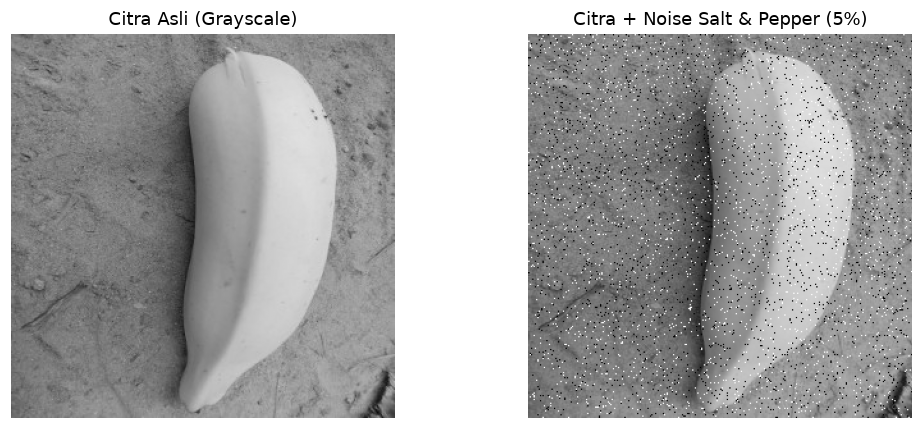

In [5]:
# Tampilkan citra asli vs noisy
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img_gray, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Citra Asli (Grayscale)')
axes[0].axis('off')
axes[1].imshow(img_noisy, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Citra + Noise Salt & Pepper (5%)')
axes[1].axis('off')
plt.tight_layout()
plt.show()


## Bagian 4 — Implementasi Konvolusi Manual

Sebelum menerapkan filter, kita implementasikan fungsi **konvolusi 2D secara manual** menggunakan operasi matriks (tanpa `cv2.filter2D()`).

### Rumus Konvolusi Spasial:

$$g(x, y) = \sum_{i=-k}^{k} \sum_{j=-k}^{k} h(i,j) \cdot f(x+i, y+j)$$

- $f$ = citra input
- $h$ = kernel/mask filter
- $g$ = citra output
- $k$ = setengah ukuran kernel (untuk 3×3, $k=1$)


In [6]:
def konvolusi_manual(citra, kernel, padding_mode='reflect'):
    """
    Implementasi konvolusi 2D manual.
    Output di-clip ke rentang [0, 255] dengan tipe uint8.
    """
    H, W = citra.shape
    kH, kW = kernel.shape
    pad_h = kH // 2
    pad_w = kW // 2

    citra_pad = np.pad(citra.astype(np.float64), ((pad_h, pad_h), (pad_w, pad_w)), mode=padding_mode)
    output = np.zeros((H, W), dtype=np.float64)

    for i in range(H):
        for j in range(W):
            region = citra_pad[i:i + kH, j:j + kW]
            output[i, j] = np.sum(region * kernel)

    return np.clip(output, 0, 255).astype(np.uint8)


## Bagian 5 — Mean Filter (Filter Rata-Rata)

**Mean filter** mengganti setiap piksel dengan **rata-rata** piksel tetangganya.

### Kernel Mean Filter 3×3:

$$H_{mean} = \frac{1}{9} \begin{bmatrix} 1 & 1 & 1 \\ 1 & 1 & 1 \\ 1 & 1 & 1 \end{bmatrix}$$

Semua bobot sama → setiap tetangga berkontribusi sama besar.


In [7]:
kernel_mean_3x3 = np.ones((3, 3), dtype=np.float64) / 9.0
kernel_mean_5x5 = np.ones((5, 5), dtype=np.float64) / 25.0
kernel_mean_7x7 = np.ones((7, 7), dtype=np.float64) / 49.0

print("Kernel Mean 3x3:\n", kernel_mean_3x3)


Kernel Mean 3x3:
 [[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


In [8]:
hasil_mean_3x3 = konvolusi_manual(img_noisy, kernel_mean_3x3)
hasil_mean_5x5 = konvolusi_manual(img_noisy, kernel_mean_5x5)
hasil_mean_7x7 = konvolusi_manual(img_noisy, kernel_mean_7x7)

val_mean_3x3 = cv2.blur(img_noisy, (3, 3))
mad_val = np.abs(hasil_mean_3x3.astype(int) - val_mean_3x3.astype(int)).mean()
print(f"Validasi Mean 3x3 vs cv2.blur: MAD = {mad_val:.4f}")


Validasi Mean 3x3 vs cv2.blur: MAD = 0.4767


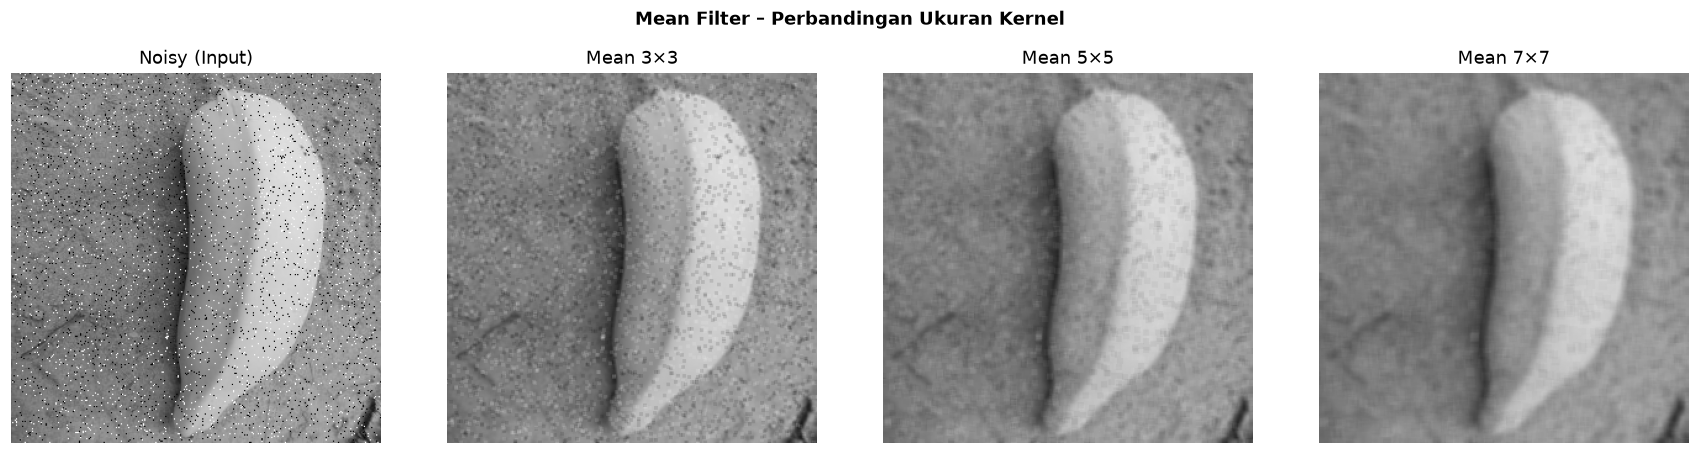

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
titles = ['Noisy (Input)', 'Mean 3×3', 'Mean 5×5', 'Mean 7×7']
images = [img_noisy, hasil_mean_3x3, hasil_mean_5x5, hasil_mean_7x7]

for ax, title, image in zip(axes, titles, images):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')

plt.suptitle('Mean Filter – Perbandingan Ukuran Kernel', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## Bagian 6 — Gaussian Filter

**Gaussian filter** menggunakan bobot yang mengikuti distribusi Gaussian 2D.  
Piksel di tengah mendapat bobot terbesar; bobot menurun seiring jarak dari pusat.

### Fungsi Gaussian 2D:

$$G(x, y) = e^{-\frac{x^2 + y^2}{2\sigma^2}}$$

- $\sigma$ (sigma) menentukan **derajat pelembutan**: semakin besar $\sigma$, semakin blur
- Filter kemudian dinormalisasi agar jumlah koefisien = 1

### Perbandingan dengan Mean Filter:
- Mean filter: semua tetangga bobot sama → artefak kotak
- Gaussian filter: bobot menyebar Gaussian → lebih natural, tepi lebih terjaga


In [10]:
def buat_kernel_gaussian(ukuran, sigma):
    """Buat kernel Gaussian 2D ternormalisasi (jumlah bobot = 1)."""
    k = ukuran // 2
    xs = np.arange(-k, k + 1, dtype=np.float64)
    ys = np.arange(-k, k + 1, dtype=np.float64)
    X, Y = np.meshgrid(xs, ys)

    kernel = np.exp(-(X**2 + Y**2) / (2 * sigma**2))
    return kernel / kernel.sum()

kernel_gauss_5x5_s1 = buat_kernel_gaussian(5, sigma=1.0)
np.set_printoptions(precision=4, suppress=True)
print("Kernel Gaussian 5x5 (sigma=1):\n", kernel_gauss_5x5_s1)


Kernel Gaussian 5x5 (sigma=1):
 [[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]


In [11]:
kernel_int = np.round(kernel_gauss_5x5_s1 * 41).astype(int)
print("Kernel Gaussian 5x5 (integer x41):\n", kernel_int)


Kernel Gaussian 5x5 (integer x41):
 [[0 1 1 1 0]
 [1 2 4 2 1]
 [1 4 7 4 1]
 [1 2 4 2 1]
 [0 1 1 1 0]]


In [12]:
kernel_g3_s1 = buat_kernel_gaussian(3, sigma=1.0)
kernel_g5_s1 = buat_kernel_gaussian(5, sigma=1.0)
kernel_g5_s2 = buat_kernel_gaussian(5, sigma=2.0)
kernel_g7_s3 = buat_kernel_gaussian(7, sigma=3.0)

hasil_gauss_3s1 = konvolusi_manual(img_noisy, kernel_g3_s1)
hasil_gauss_5s1 = konvolusi_manual(img_noisy, kernel_g5_s1)
hasil_gauss_5s2 = konvolusi_manual(img_noisy, kernel_g5_s2)
hasil_gauss_7s3 = konvolusi_manual(img_noisy, kernel_g7_s3)

val_gauss = cv2.GaussianBlur(img_noisy, (5, 5), sigmaX=1.0)
mad_gauss = np.abs(hasil_gauss_5s1.astype(int) - val_gauss.astype(int)).mean()
print(f"Validasi Gaussian 5x5 (sigma=1) vs cv2.GaussianBlur: MAD = {mad_gauss:.4f}")


Validasi Gaussian 5x5 (sigma=1) vs cv2.GaussianBlur: MAD = 0.5002


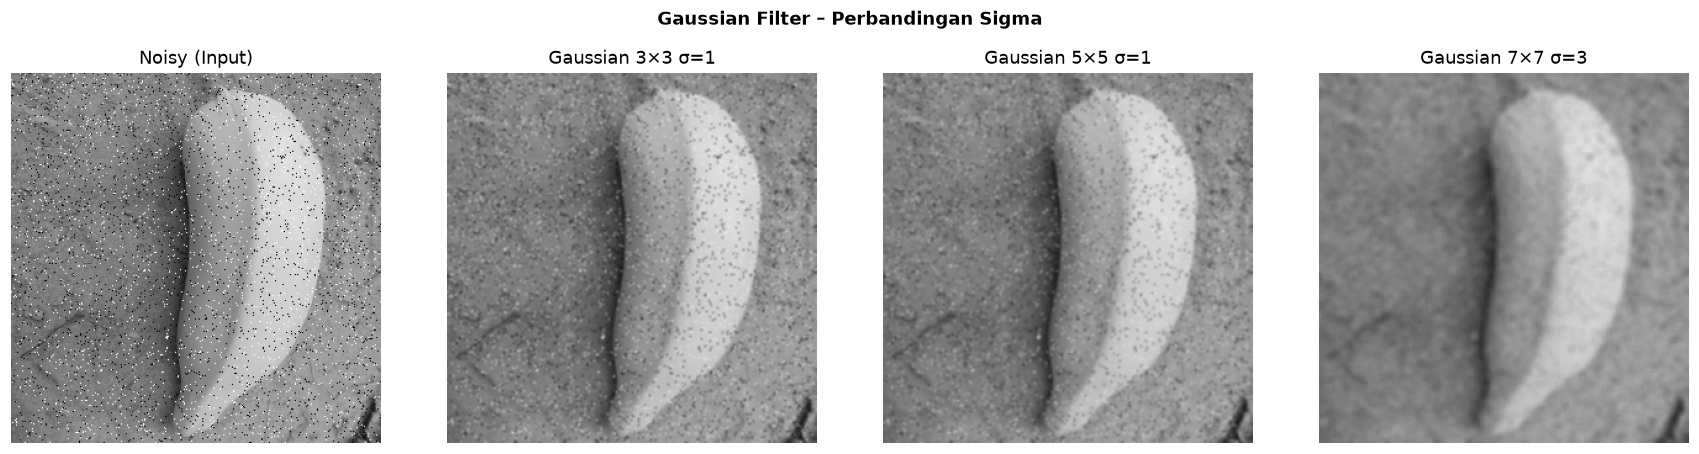

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
titles = ['Noisy (Input)', 'Gaussian 3×3 σ=1', 'Gaussian 5×5 σ=1', 'Gaussian 7×7 σ=3']
images = [img_noisy, hasil_gauss_3s1, hasil_gauss_5s1, hasil_gauss_7s3]

for ax, title, image in zip(axes, titles, images):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')

plt.suptitle('Gaussian Filter – Perbandingan Sigma', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## Bagian 7 — Median Filter (Filter Nonlinier)

**Median filter** adalah filter **nonlinier** yang mengganti setiap piksel dengan **nilai median** dari tetangganya.

### Karakteristik:
- Sangat efektif untuk noise **salt & pepper**
- Lebih baik menjaga tepi dibandingkan mean/Gaussian filter
- **Tidak bisa direpresentasikan sebagai kernel** (karena nonlinier — menggunakan operasi sort, bukan perkalian)

### Cara Kerja:
1. Ambil $n 	imes n$ window di sekitar piksel
2. Urutkan semua nilai piksel dalam window
3. Ambil nilai tengah (median) sebagai nilai output piksel


In [14]:
def median_filter_manual(citra, ukuran=3):
    """
    Median filter manual (nonlinier berbasis sorting).
    Output bertipe uint8.
    """
    H, W = citra.shape
    pad = ukuran // 2
    citra_pad = np.pad(citra, pad, mode='reflect')
    output = np.zeros_like(citra)

    for i in range(H):
        for j in range(W):
            window = citra_pad[i:i + ukuran, j:j + ukuran]
            output[i, j] = np.median(window)

    return output


In [15]:
hasil_median_3x3 = median_filter_manual(img_noisy, ukuran=3)
hasil_median_5x5 = median_filter_manual(img_noisy, ukuran=5)

val_median = cv2.medianBlur(img_noisy, 3)
mad_median = np.abs(hasil_median_3x3.astype(int) - val_median.astype(int)).mean()
print(f"Validasi Median 3x3 vs cv2.medianBlur: MAD = {mad_median:.4f}")


Validasi Median 3x3 vs cv2.medianBlur: MAD = 0.0412


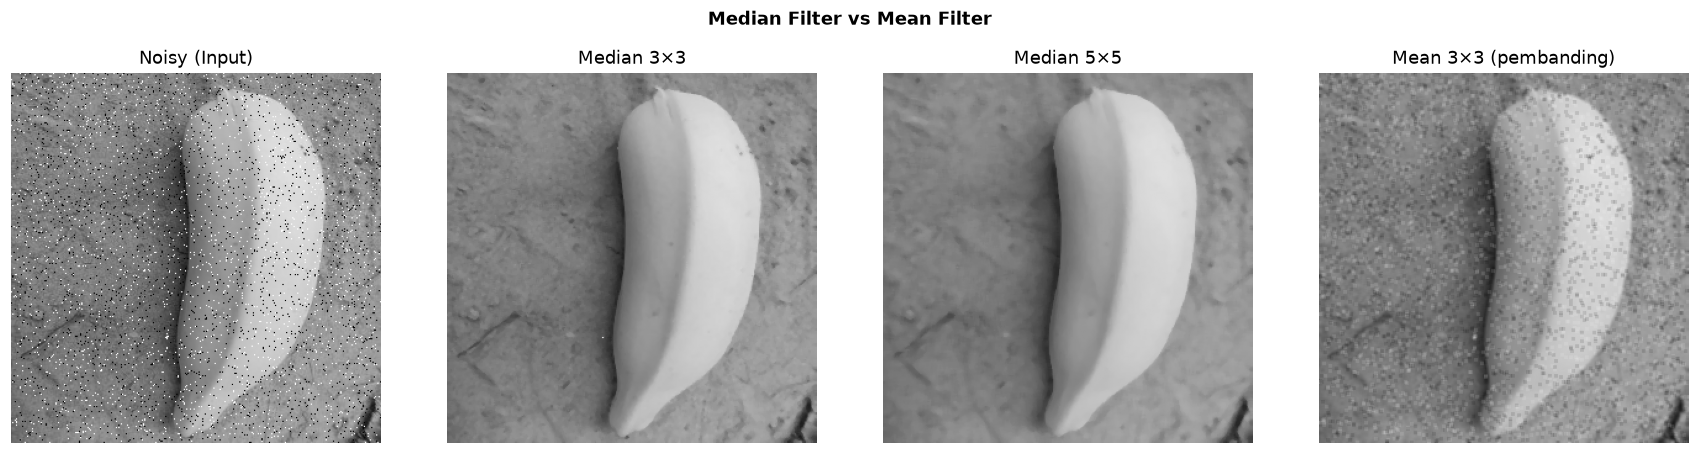

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
titles = ['Noisy (Input)', 'Median 3×3', 'Median 5×5', 'Mean 3×3 (pembanding)']
images = [img_noisy, hasil_median_3x3, hasil_median_5x5, hasil_mean_3x3]

for ax, title, image in zip(axes, titles, images):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')

plt.suptitle('Median Filter vs Mean Filter', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## Bagian 8 — Perbandingan Lengkap Semua Filter

Membandingkan semua metode smoothing secara side-by-side dalam satu figure.


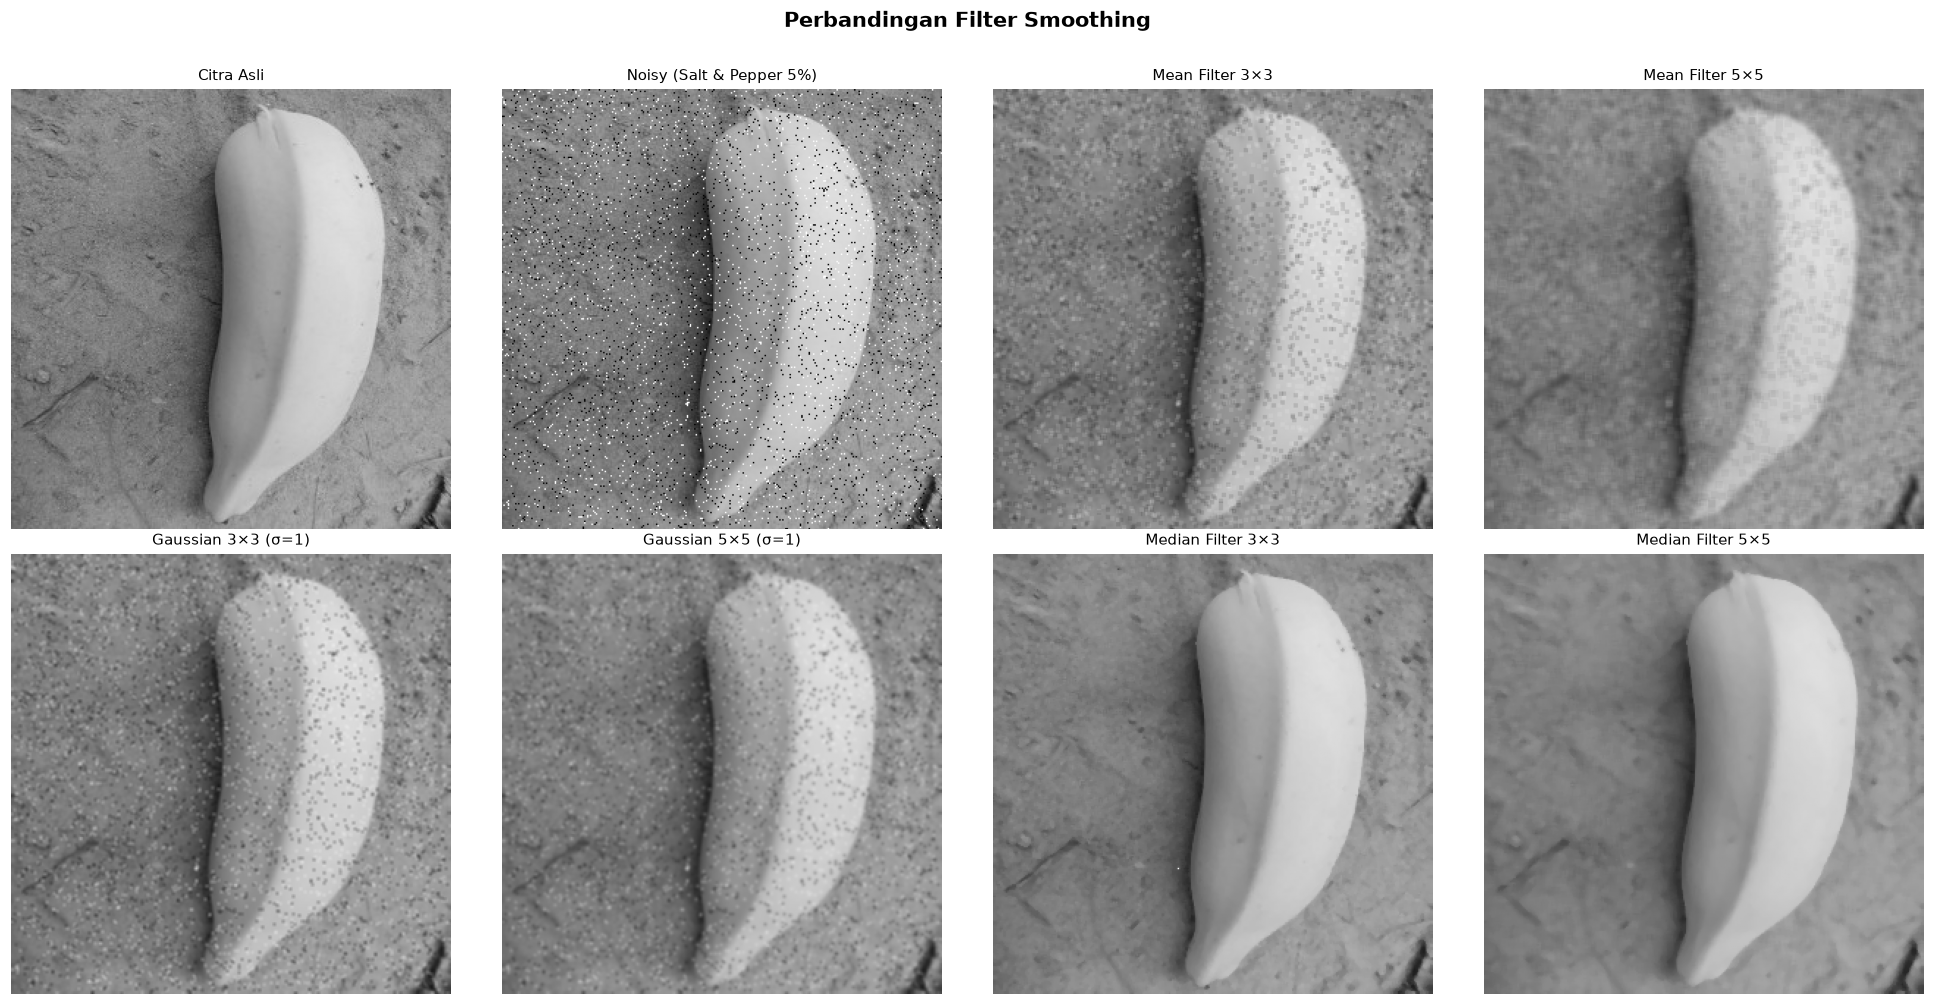

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle('Perbandingan Filter Smoothing', fontsize=14, fontweight='bold', y=1.01)

metode = [
    (img_gray,         'Citra Asli'),
    (img_noisy,        'Noisy (Salt & Pepper 5%)'),
    (hasil_mean_3x3,   'Mean Filter 3×3'),
    (hasil_mean_5x5,   'Mean Filter 5×5'),
    (hasil_gauss_3s1,  'Gaussian 3×3 (σ=1)'),
    (hasil_gauss_5s1,  'Gaussian 5×5 (σ=1)'),
    (hasil_median_3x3, 'Median Filter 3×3'),
    (hasil_median_5x5, 'Median Filter 5×5'),
]

for ax, (img, title) in zip(axes.ravel(), metode):
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title, fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig('hasil_output/perbandingan_smoothing.png', dpi=200, bbox_inches='tight')
plt.show()


## Bagian 9 — Analisis Kuantitatif

Mengukur kualitas hasil filter secara objektif menggunakan:
- **MSE** (Mean Squared Error): rata-rata kuadrat perbedaan piksel
- **PSNR** (Peak Signal-to-Noise Ratio): semakin tinggi → semakin mirip dengan citra asli


In [18]:
def hitung_mse(citra_asli, citra_hasil):
    return np.mean((citra_asli.astype(float) - citra_hasil.astype(float))**2)

def hitung_psnr(citra_asli, citra_hasil):
    mse = hitung_mse(citra_asli, citra_hasil)
    if mse == 0:
        return float('inf')
    return 10 * np.log10(255**2 / mse)

# Hitung untuk semua metode
hasil_list = [
    ('Noisy (tanpa filter)',  img_noisy),
    ('Mean 3×3',              hasil_mean_3x3),
    ('Mean 5×5',              hasil_mean_5x5),
    ('Mean 7×7',              hasil_mean_7x7),
    ('Gaussian 3×3 σ=1',     hasil_gauss_3s1),
    ('Gaussian 5×5 σ=1',     hasil_gauss_5s1),
    ('Gaussian 5×5 σ=2',     hasil_gauss_5s2),
    ('Median 3×3',            hasil_median_3x3),
    ('Median 5×5',            hasil_median_5x5),
]

print(f"{'Metode':<26} {'MSE':>8} {'PSNR (dB)':>12}")
print('-' * 50)
for nama, hasil in hasil_list:
    mse  = hitung_mse(img_gray, hasil)
    psnr = hitung_psnr(img_gray, hasil)
    print(f"{nama:<26} {mse:>8.2f} {psnr:>12.2f}")


Metode                          MSE    PSNR (dB)
--------------------------------------------------
Noisy (tanpa filter)         866.69        18.75
Mean 3×3                     138.23        26.72
Mean 5×5                      95.70        28.32
Mean 7×7                      91.99        28.49
Gaussian 3×3 σ=1             142.27        26.60
Gaussian 5×5 σ=1             110.71        27.69
Gaussian 5×5 σ=2              92.34        28.48
Median 3×3                    36.58        32.50
Median 5×5                    51.52        31.01
